# Лабораторна 1

Датасет: MAGIC Gamma Telescope
https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope

Дані з гамма-телескопа MAGIC (згенеровані симуляцією). Телескоп бачить спалахи світла в атмосфері, по формі спалаху (еліпс на камері) треба зрозуміти, що його викликало - гамма-квант (g) чи адрон (h). Адрони це по суті фон, який треба відсіяти.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 1. Завантаження даних

In [2]:
cols = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
df = pd.read_csv('magic04.data', header=None, names=cols)
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [3]:
print(df.shape)
print(df.columns)

(19020, 11)
Index(['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long',
       'fM3Trans', 'fAlpha', 'fDist', 'class'],
      dtype='str')


В файлі немає заголовків, назви колонок взяв з magic04.names.

fLength, fWidth - довжина і ширина еліпса, fSize - яскравість, fConc/fConc1 - яка частка світла в найяскравіших пікселях, fAsym, fM3Long, fM3Trans - асиметрія, fAlpha - кут еліпса відносно центру камери, fDist - відстань від центру.

Ознаки - перші 10 колонок, ціль - class.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  str    
dtypes: float64(10), str(1)
memory usage: 1.6 MB


In [5]:
df.describe()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


class
g    12332
h     6688
Name: count, dtype: int64


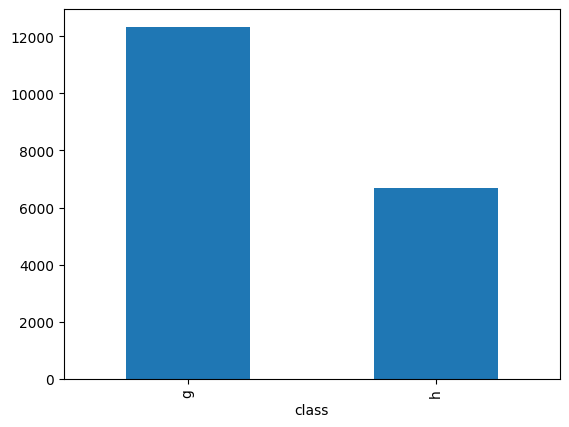

In [6]:
print(df['class'].value_counts())
df['class'].value_counts().plot(kind='bar')
plt.show()

Всі ознаки float, class - текст. Гамми майже вдвічі більше ніж адронів (12332 проти 6688), тобто класи не збалансовані.

## 2. Попередня обробка

In [7]:
print(df.isna().sum())

fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
class       0
dtype: int64


In [8]:
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

115
(18905, 11)


In [9]:
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])
print(le.classes_)
df['class'].value_counts()

['g' 'h']


class
0    12332
1     6573
Name: count, dtype: int64

Пропусків нема. Знайшлось 115 дублікатів - видалив, щоб вони не попали одночасно і в train і в test.
Категоріальних ознак нема, тільки ціль перевів в числа: g = 0, h = 1.
Викиди не чіпав, бо великі значення (довгі широкі еліпси) як раз частіше у адронів.

## 3. EDA

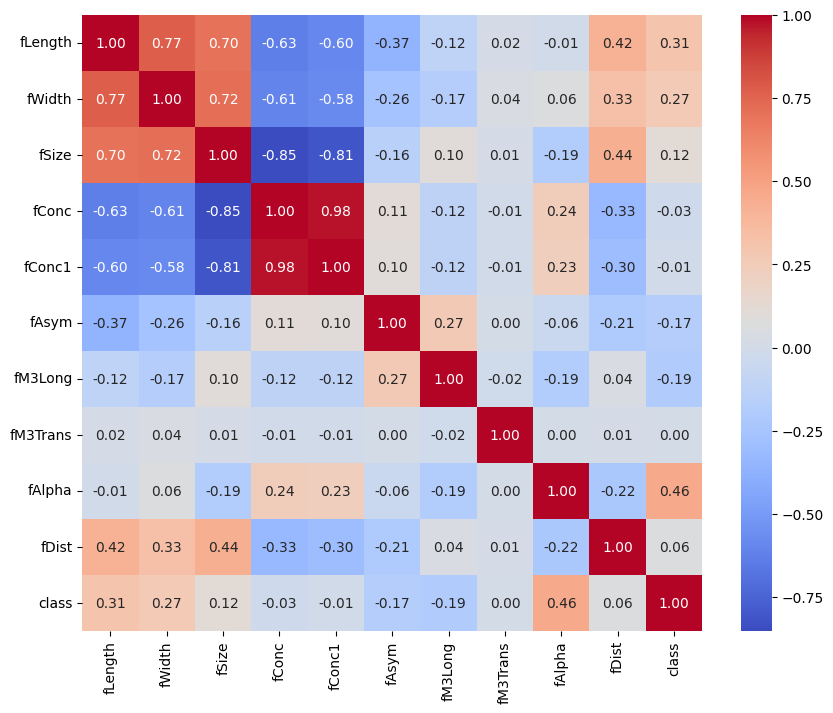

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

fConc і fConc1 корелюють майже на 1, і обидві сильно відʼємно з fSize. fLength, fWidth, fSize теж між собою повʼязані.
З class найбільше корелює fAlpha (0.46), потім fLength і fWidth.

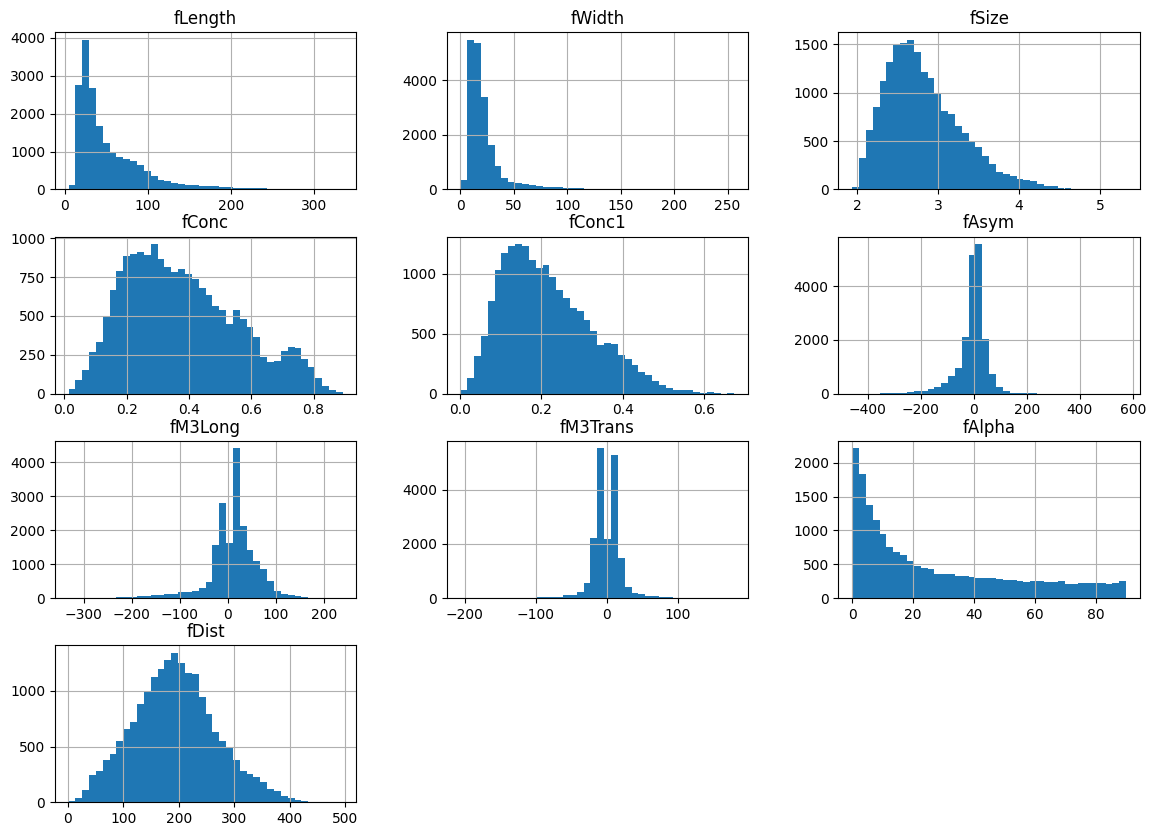

In [11]:
df.drop(columns='class').hist(bins=40, figsize=(14, 10))
plt.show()

Більшість ознак скошені вправо і з довгими хвостами (fLength, fWidth, fDist). Масштаби дуже різні, тому для kNN і SVM треба буде scaler.

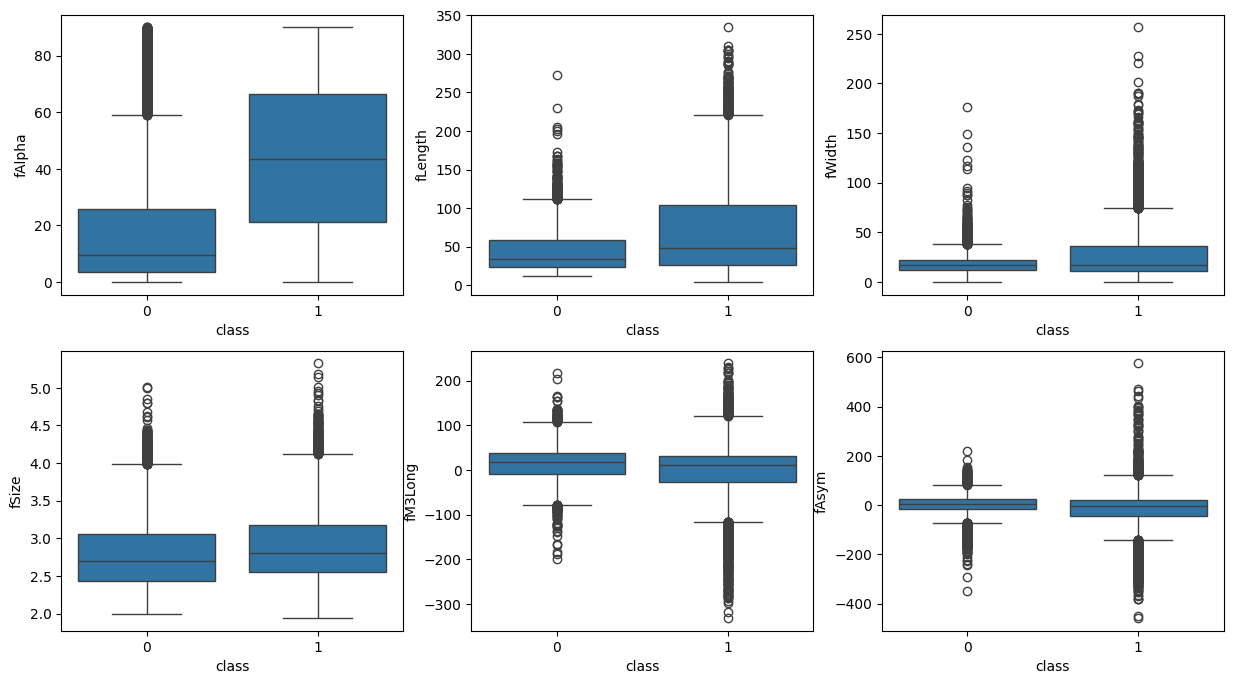

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.boxplot(data=df, x='class', y='fAlpha', ax=axes[0, 0])
sns.boxplot(data=df, x='class', y='fLength', ax=axes[0, 1])
sns.boxplot(data=df, x='class', y='fWidth', ax=axes[0, 2])
sns.boxplot(data=df, x='class', y='fSize', ax=axes[1, 0])
sns.boxplot(data=df, x='class', y='fM3Long', ax=axes[1, 1])
sns.boxplot(data=df, x='class', y='fAsym', ax=axes[1, 2])
plt.show()

(0 - гамма, 1 - адрон)

Найкраще розділяє fAlpha: у гамми кут маленький, бо гамма летить прямо від джерела, а адрони летять з усіх сторін і кут у них будь-який.
У адронів еліпси довші і ширші (fLength, fWidth), і там купа викидів. fSize майже однаковий.
Брав тільки 6 ознак, які найбільше корелюють з class.

## 4. Підготовка даних

In [13]:
X = df.drop(columns='class')
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(14178, 10) (4727, 10)


In [14]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
X_train_s[:3]

array([[-0.08204831,  0.33113385,  0.93452144, -1.11307004, -1.1359361 ,
         0.81305776,  0.30614264,  1.0874212 , -1.03252665, -0.57359537],
       [-0.82031448, -0.65863546, -1.19586196,  1.30105728,  0.95081926,
         0.45704418, -0.00432034, -0.29578084, -0.25963637,  0.32064947],
       [-0.61605777, -0.65018634, -0.1162068 ,  1.02490654,  0.63151946,
         0.59466924,  0.24478116, -0.59661842, -0.03562778, -0.10449408]])

75% train, 25% test, stratify щоб пропорція класів збереглась.
Scaler навчаю тільки на train. Масштабовані дані для kNN і SVM, для дерев не треба.

## 5. Навчання моделей

In [15]:
knn = KNeighborsClassifier()
knn.fit(X_train_s, y_train)
print('knn', accuracy_score(y_test, knn.predict(X_test_s)))

knn 0.8368944362174741


In [16]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
print('tree', accuracy_score(y_test, dt.predict(X_test)))

tree

 0.8144700655807066


In [17]:
svm = SVC()
svm.fit(X_train_s, y_train)
print('svm', accuracy_score(y_test, svm.predict(X_test_s)))

svm 0.8696847895070869


In [18]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
print('random forest', accuracy_score(y_test, rf.predict(X_test)))

random forest 0.8847048868203935


In [19]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)
print('adaboost', accuracy_score(y_test, ada.predict(X_test)))

adaboost 0.8356251322191665


З дефолтними параметрами найкраще Random Forest (0.885) і SVM (0.870), найгірше дерево (0.814).

## 6. Підбір гіперпараметрів

### kNN

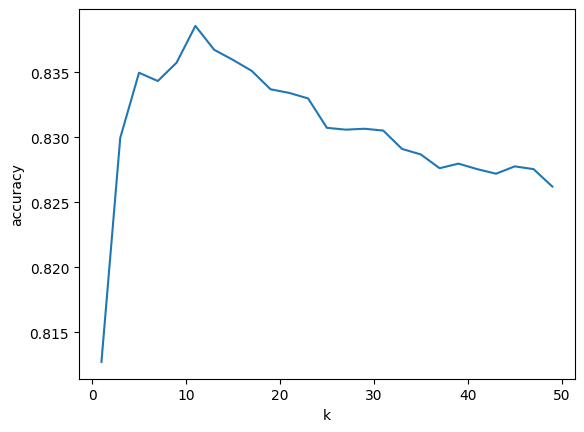

best k = 11 0.8385529461222927


In [20]:
scores = []
for k in range(1, 50, 2):
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5)
    scores.append(s.mean())

plt.plot(range(1, 50, 2), scores)
plt.xlabel('k')
plt.ylabel('accuracy')
plt.show()

best_k = range(1, 50, 2)[np.argmax(scores)]
print('best k =', best_k, max(scores))

Брав тільки непарні k щоб не було нічиєї. При k=1 модель перенавчається, потім accuracy росте, найкраще при k = 11, а далі потроху падає.

### SVM

In [21]:
params = {'C': [1, 10, 100], 'gamma': [0.01, 0.1, 0.5, 1]}
grid = GridSearchCV(SVC(), params, cv=3, n_jobs=-1)
grid.fit(X_train_s, y_train)
print(grid.best_params_)
print(grid.best_score_)

{'C': 10, 'gamma': 0.1}
0.8717026378896883


In [22]:
res = pd.DataFrame(grid.cv_results_)
res[['param_C', 'param_gamma', 'mean_test_score']].sort_values('mean_test_score', ascending=False)

,param_C,param_gamma,mean_test_score
5,10,0.10,0.871703
9,100,0.10,0.870856
8,100,0.01,0.865566
1,1,0.10,0.864932
2,1,0.50,0.864791
6,10,0.50,0.861476
4,10,0.01,0.861405
3,1,1.00,0.859712
7,10,1.00,0.847369
10,100,0.50,0.845183


Найкраще C=10, gamma=0.1. Якщо gamma велика (1) і C велике, то модель перенавчається і результат гірший (100 і 1 - взагалі найгірше, 0.825).
cv=3 замість 5, бо SVM довго вчиться.

### Decision Tree

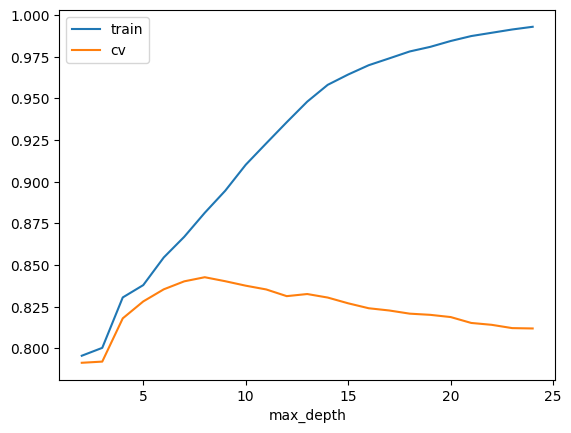

best depth = 8 0.842714556856541


In [23]:
train_acc = []
cv_acc = []
for d in range(2, 25):
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_acc.append(cross_val_score(tree, X_train, y_train, cv=5).mean())
    tree.fit(X_train, y_train)
    train_acc.append(tree.score(X_train, y_train))

plt.plot(range(2, 25), train_acc, label='train')
plt.plot(range(2, 25), cv_acc, label='cv')
plt.xlabel('max_depth')
plt.legend()
plt.show()

best_depth = range(2, 25)[np.argmax(cv_acc)]
print('best depth =', best_depth, max(cv_acc))

Чим глибше дерево, тим ближче train до 100%, а на cv після глибини 8 стає гірше - перенавчання. Беру max_depth = 8.

### Random Forest

In [24]:
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), {'n_estimators': [100, 300], 'max_depth': [10, 20, None]}, cv=3, n_jobs=-1)
grid_rf.fit(X_train, y_train)
print(grid_rf.best_params_, grid_rf.best_score_)

{'max_depth': None, 'n_estimators': 300} 0.8760756101001551


### AdaBoost

In [25]:
grid_ada = GridSearchCV(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), random_state=42),
    {'n_estimators': [50, 100, 300], 'learning_rate': [0.1, 0.5, 1.0]},
    cv=3,
    n_jobs=-1,
)
grid_ada.fit(X_train, y_train)
print(grid_ada.best_params_, grid_ada.best_score_)

{'learning_rate': 1.0, 'n_estimators': 300} 0.8673296656792213


Для RF підбір майже нічого не дав, дефолт і так був норм.
AdaBoost з дефолтними пеньками (глибина 1) давав 0.836, з деревами глибини 3 і 300 штук став 0.867.

## 7. Порівняння моделей

In [26]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
svm = grid.best_estimator_
rf = grid_rf.best_estimator_
ada = grid_ada.best_estimator_

pred = {
    'kNN': knn.predict(X_test_s),
    'Decision Tree': dt.predict(X_test),
    'SVM': svm.predict(X_test_s),
    'Random Forest': rf.predict(X_test),
    'AdaBoost': ada.predict(X_test),
}

In [27]:
for name in pred:
    print(name)
    print(classification_report(y_test, pred[name], target_names=['g', 'h']))
    print(confusion_matrix(y_test, pred[name]))
    print('------------------------------')

kNN
              precision    recall  f1-score   support

           g       0.82      0.96      0.89      3083
           h       0.90      0.61      0.73      1644

    accuracy                           0.84      4727
   macro avg       0.86      0.79      0.81      4727
weighted avg       0.85      0.84      0.83      4727

[[2966  117]
 [ 634 1010]]
------------------------------
Decision Tree
              precision    recall  f1-score   support

           g       0.84      0.94      0.89      3083
           h       0.85      0.67      0.75      1644

    accuracy                           0.85      4727
   macro avg       0.85      0.80      0.82      4727
weighted avg       0.85      0.85      0.84      4727

[[2895  188]
 [ 542 1102]]
------------------------------
SVM
              precision    recall  f1-score   support

           g       0.86      0.96      0.91      3083
           h       0.91      0.71      0.80      1644

    accuracy                           0.87 

kNN              0.841125
Decision Tree    0.845568
AdaBoost         0.867358
SVM              0.874762
Random Forest    0.884493
dtype: float64


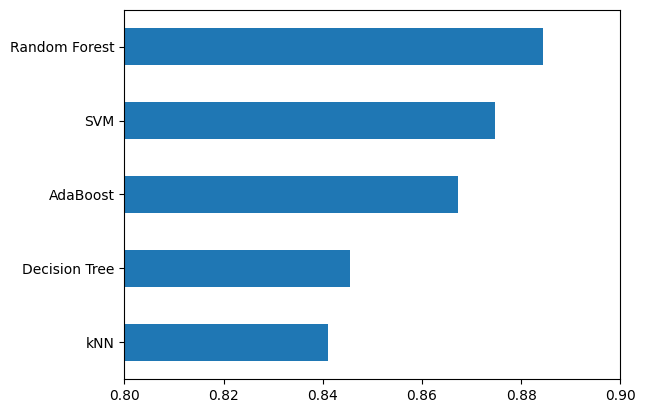

In [28]:
acc = {name: accuracy_score(y_test, pred[name]) for name in pred}
acc = pd.Series(acc).sort_values()
print(acc)
acc.plot(kind='barh')
plt.xlim(0.8, 0.9)
plt.show()

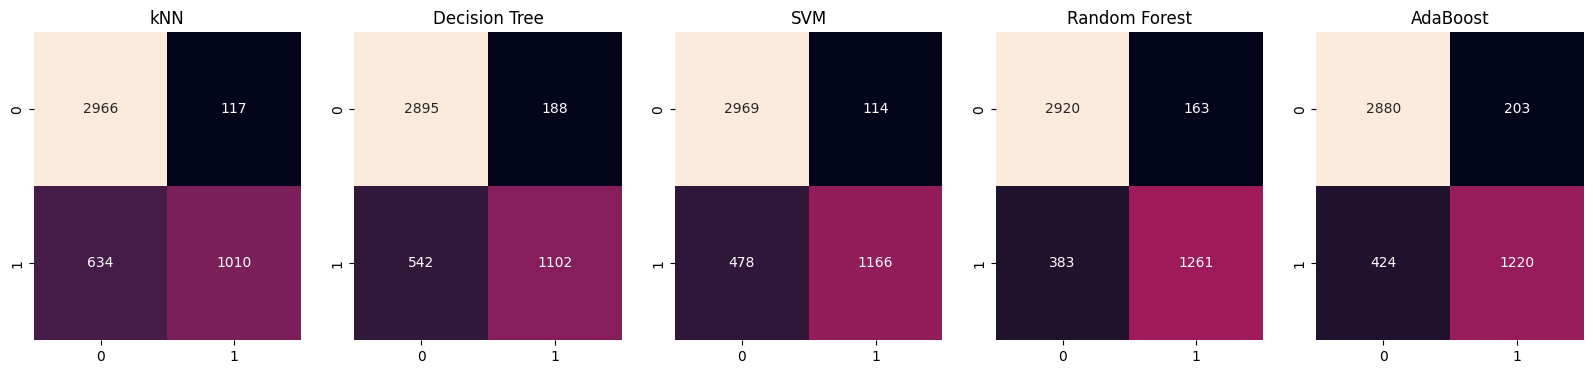

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
i = 0
for name in pred:
    sns.heatmap(confusion_matrix(y_test, pred[name]), annot=True, fmt='d', cbar=False, ax=axes[i])
    axes[i].set_title(name)
    i += 1
plt.show()

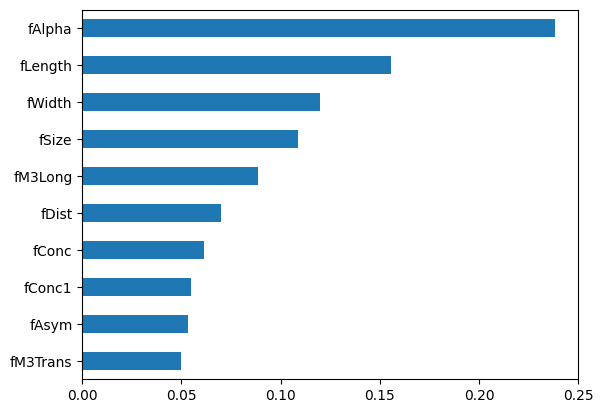

In [30]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind='barh')
plt.show()

У всіх моделей та сама проблема: гамму знаходять добре (recall 0.93-0.96), а адронів пропускають багато (recall 0.61-0.77). Тобто частіше всього помилка - адрон прийняли за гамму.
У kNN найгірший recall по адронах (0.61). У SVM найбільша precision по h (0.91), але адронів він пропускає більше ніж RF.
По важливості ознак у RF на першому місці fAlpha, потім fLength і fWidth - те саме що було видно на boxplot.

## Висновок

Найкраще себе показав Random Forest - accuracy 0.884, і в нього найкращий recall по адронах (0.77). На другому місці SVM (0.875), потім AdaBoost (0.867), дерево і kNN десь 0.84.

Чому RF: межа між класами нелінійна і по одній ознаці класи не розділити, треба комбінувати кілька, а дерева це вміють. Викиди і різні масштаби деревам не заважають. Одне дерево перенавчається, а в RF багато дерев усереднюються і цього нема.

kNN гірше, бо він рахує відстань по всіх ознаках однаково, навіть по тих які майже нічого не дають (fM3Trans, fConc1).